In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

MODE = "test"
assert MODE in ["test", "full"]

sn = pd.read_csv("../_supernova/processed/sn.csv")
bao = pd.read_csv("../_bao/processed/bao.csv")

sn_cov = np.load(
    "../_supernova/processed/sn_covariance.npz"
)["covariance"]
bao_cov = np.load(
    "../_bao/processed/bao_covariance.npz"
)["covariance"]

z_sn = sn["zHD"].values
z_hel = sn["zHEL"].values
m = sn["m_b_corr"].values

z_bao = bao["z"].values
y = bao["value"].values
quantity = bao["quantity"].values

assert sn_cov.shape == (len(sn), len(sn))
assert bao_cov.shape == (len(bao), len(bao))

prefix = "results/wcdm_" + MODE

In [2]:
if MODE == "test":
    omega_grid = np.linspace(0.05, 0.60, 29)
    w_grid = np.linspace(-1.80, -0.30, 31)
else:
    omega_grid = np.linspace(0.05, 0.60, 221)
    w_grid = np.linspace(-1.80, -0.30, 151)

parameters = pd.DataFrame(
    [(om, w) for w in w_grid for om in omega_grid],
    columns=["Omega_m", "w"],
)

pd.DataFrame({
    "mode": [MODE],
    "models": [len(parameters)],
    "Omega_m_step": [omega_grid[1] - omega_grid[0]],
    "w_step": [w_grid[1] - w_grid[0]],
})

,mode,models,Omega_m_step,w_step
0,test,899,0.019643,0.05


In [3]:
z_grid = np.linspace(0, max(max(z_sn), max(z_bao)), 4001)
dz = z_grid[1] - z_grid[0]

sn_shape = np.zeros((len(sn), len(parameters)))
bao_shape = np.zeros((len(bao), len(parameters)))

for j, (om, w) in enumerate(parameters.values):
    inv_e = 1 / (
        om * (1 + z_grid)**3
        + (1 - om) * (1 + z_grid)**(3 * (1 + w))
    )**0.5

    integral = np.zeros(len(z_grid))
    integral[1:] = np.cumsum(
        (inv_e[:-1] + inv_e[1:]) * dz / 2
    )

    distance_sn = (
        (1 + z_hel) * np.interp(z_sn, z_grid, integral)
    )
    sn_shape[:, j] = 5 * np.log10(distance_sn)

    dm = np.interp(z_bao, z_grid, integral)

    dh = 1 / (
        om * (1 + z_bao)**3
        + (1 - om) * (1 + z_bao)**(3 * (1 + w))
    )**0.5

    dv = (z_bao * dm**2 * dh)**(1 / 3)

    bao_shape[quantity == "DM_over_rs", j] = dm[quantity == "DM_over_rs"]
    bao_shape[quantity == "DH_over_rs", j] = dh[quantity == "DH_over_rs"]
    bao_shape[quantity == "DV_over_rs", j] = dv[quantity == "DV_over_rs"]

In [4]:
white = np.linalg.solve(
    np.linalg.cholesky(sn_cov),
    np.column_stack((np.ones(len(sn)), m, sn_shape)),
)

u = white[:, 0]
delta = white[:, 1].reshape(-1, 1) - white[:, 2:]

sn_offset = (u @ delta) / (u @ u)
delta -= u.reshape(-1, 1) * sn_offset

sn_chi2 = np.sum(delta**2, axis=0)

del white, delta, sn_shape

In [5]:
white = np.linalg.solve(
    np.linalg.cholesky(bao_cov),
    np.column_stack((y, bao_shape)),
)

y_white = white[:, 0]
templates = white[:, 1:]

bao_scale = (
    (y_white @ templates)
    / np.sum(templates**2, axis=0)
)

residual = y_white.reshape(-1, 1) - templates * bao_scale
bao_chi2 = np.sum(residual**2, axis=0)

joint_chi2 = sn_chi2 + bao_chi2

profile = parameters.copy()
profile["sn_offset"] = sn_offset
profile["bao_A"] = bao_scale
profile["sn_chi2"] = sn_chi2
profile["bao_chi2"] = bao_chi2
profile["joint_chi2"] = joint_chi2

profile.to_csv(prefix + "_grid.csv", index=False)

In [6]:
def profile_interval(grid, chi2):
    best = np.argmin(chi2)
    delta = chi2 - chi2[best]

    lower = np.nan
    upper = np.nan

    if best > 0 and delta[0] > 1:
        lower = np.interp(
            1, delta[:best + 1][::-1], grid[:best + 1][::-1]
        )

    if best < len(grid) - 1 and delta[-1] > 1:
        upper = np.interp(
            1, delta[best:], grid[best:]
        )

    return lower, upper


rows = []

for name, chi2 in [
    ("SN", sn_chi2),
    ("BAO", bao_chi2),
    ("SN + BAO", joint_chi2),
]:
    surface = chi2.reshape(len(w_grid), len(omega_grid))
    best = np.argmin(chi2)

    omega_profile = np.min(surface, axis=0)
    w_profile = np.min(surface, axis=1)

    om_low, om_high = profile_interval(omega_grid, omega_profile)
    w_low, w_high = profile_interval(w_grid, w_profile)

    rows.append({
        "data": name,
        "Omega_m": parameters.loc[best, "Omega_m"],
        "Omega_m_lower_68": om_low,
        "Omega_m_upper_68": om_high,
        "w": parameters.loc[best, "w"],
        "w_lower_68": w_low,
        "w_upper_68": w_high,
        "chi2": chi2[best],
    })

summary = pd.DataFrame(rows)
summary.to_csv(prefix + "_summary.csv", index=False)

summary

,data,Omega_m,Omega_m_lower_68,Omega_m_upper_68,w,w_lower_68,w_upper_68,chi2
0,SN,0.285714,0.206980,0.348194,-0.90,-1.055321,-0.749568,1402.541962
1,BAO,0.305357,0.288004,0.307783,-0.90,-0.988267,-0.845001,9.832344
2,SN + BAO,0.305357,0.285328,0.307683,-0.95,-0.964616,-0.875309,1412.738937


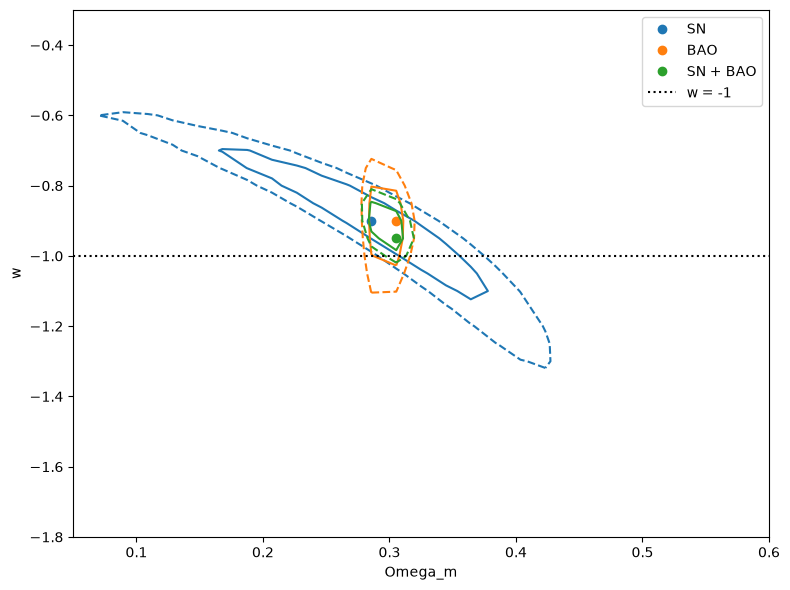

In [7]:
plt.figure(figsize=(8, 6))

for name, chi2, color in [
    ("SN", sn_chi2, "tab:blue"),
    ("BAO", bao_chi2, "tab:orange"),
    ("SN + BAO", joint_chi2, "tab:green"),
]:
    surface = chi2.reshape(len(w_grid), len(omega_grid))
    delta = surface - np.min(surface)

    plt.contour(
        omega_grid,
        w_grid,
        delta,
        levels=[2.30, 5.99],
        colors=[color],
        linestyles=["solid", "dashed"],
    )

    best = np.argmin(chi2)

    plt.plot(
        parameters.loc[best, "Omega_m"],
        parameters.loc[best, "w"],
        "o",
        color=color,
        label=name,
    )

plt.plot(
    [omega_grid[0], omega_grid[-1]],
    [-1, -1],
    "k:",
    label="w = -1",
)

plt.xlabel("Omega_m")
plt.ylabel("w")
plt.legend()
plt.tight_layout()
plt.savefig(prefix + "_contours.png", dpi=200)
plt.show()

In [8]:
lambda_mask = np.isclose(parameters["w"].values, -1)
assert lambda_mask.any()

lambda_min = np.min(joint_chi2[lambda_mask])
wcdm_min = np.min(joint_chi2)

model_comparison = pd.DataFrame({
    "model": ["Flat LCDM", "Flat wCDM"],
    "parameters": [3, 4],
    "chi2": [lambda_min, wcdm_min],
})

model_comparison["dof"] = (
    len(sn) + len(bao) - model_comparison["parameters"]
)

model_comparison["AIC"] = (
    model_comparison["chi2"]
    + 2 * model_comparison["parameters"]
)

model_comparison["delta_AIC"] = (
    model_comparison["AIC"] - min(model_comparison["AIC"])
)

model_comparison.to_csv(
    prefix + "_model_comparison.csv",
    index=False,
)

model_comparison

,model,parameters,chi2,dof,AIC,delta_AIC
0,Flat LCDM,3,1416.159897,1600,1422.159897,1.42096
1,Flat wCDM,4,1412.738937,1599,1420.738937,0.00000
